# 多目标、MMoE 与粗排
## Goal
把概念变成可检查的输入、运算、梯度与对照。

数据类型：**受控模拟，不是曝光 CTR**。本地教学参数不是生产默认值；机制实验不是原论文完整复现。

## Setup
每本首次从 Setup 起顺序运行，后面的格会复用前面的变量。之后只改一个参数，重跑对应格及下游格。不要把构造数据当作真实业务收益。

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json

plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


## Steps
讲义对应：03_Rank_01.pdf, 03_Rank_02.pdf, 03_Rank_03.pdf, 03_Rank_04.pdf, 03_Rank_05.pdf, 03_Rank_06.pdf

### 条件概率、融分与负采样校准
以下都是构造的概率。校准依赖已知采样机制，不可直接用于缺少曝光分母的日志。

**先预测：** 条件概率连乘和任意预测分数相加分别表达什么？

In [2]:
from reclab.learning.networks import (calibrate_negative_sampling,
    fit_multitask, MMoE, ThreeTower)
import torch
from torch.nn import functional as F
torch.manual_seed(42); torch.set_num_threads(4)
pc=np.array([.2,.4,.15]); cart=np.array([.3,.1,.5]); pay=np.array([.4,.6,.3]); price=np.array([20.,100.,50.])
display(pd.DataFrame({"p_pay":pc*cart*pay,"expected_revenue":pc*cart*pay*price,"weighted_sum_proxy":pc+cart+pay}))
true=np.array([.01,.1,.5]); alpha=.1
sampled=true/(true+alpha*(1-true))
recovered=calibrate_negative_sampling(sampled,alpha)
assert np.allclose(true,recovered)
display(pd.DataFrame({"true":true,"sampled":sampled,"recovered":recovered}))

,p_pay,expected_revenue,weighted_sum_proxy
0,0.0240,0.480,0.90
1,0.0240,2.400,1.10
2,0.0225,1.125,0.95


,true,sampled,recovered
0,0.01,0.091743,0.01
1,0.10,0.526316,0.10
2,0.50,0.909091,0.50


### MMoE 的任务与 Gate
受控合成标签；训练拟合不能解释为真实推荐收益。这里可直接修改任务相关度。

**先预测：** 把任务相关度改为 0，Gate 一定分开、效果一定提升吗？

class MMoE(nn.Module):
    def __init__(self, input_dim, experts=3, tasks=2, hidden=12):
        super().__init__()
        self.experts = nn.ModuleList(
            [
                nn.Sequential(nn.Linear(input_dim, hidden), nn.ReLU())
                for _ in range(experts)
            ]
        )
        self.gates = nn.ModuleList(
            [nn.Linear(input_dim, experts) for _ in range(tasks)]
        )
        self.heads = nn.ModuleList([nn.Linear(hidden, 1) for _ in range(tasks)])

    def forward(self, x):
        experts = torch.stack([expert(x) for expert in self.experts], 1)
        weights = [gate(x).softmax(-1) for gate in self.gates]
        logits = torch.cat(
            [
                head((experts * w.unsqueeze(-1)).sum(1))
                for w, head in zip(weights, self.heads)
            ],
            -1,
        )
        return logits, torch.stack(weights, 1)

,expert1,expert2,expert3
task1,0.426174,0.263568,0.310258
task2,0.389943,0.395034,0.215022


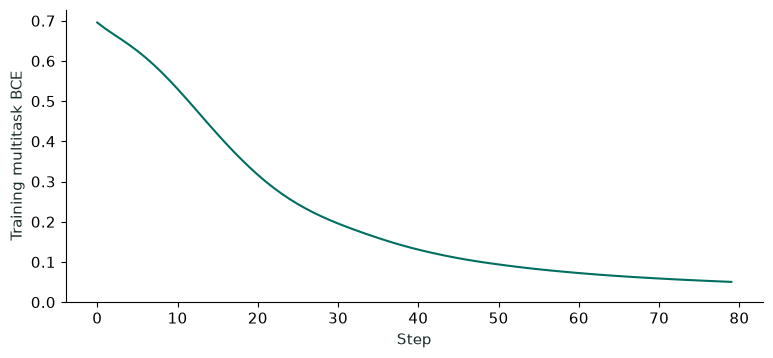

In [3]:
TASK_CORRELATION=.7
x=torch.randn(512,6); signal=x[:,0]+x[:,1]*x[:,2]
other=TASK_CORRELATION*signal+(1-TASK_CORRELATION)*(x[:,3]-x[:,4])
y=torch.stack([(signal>0).float(),(other>0).float()],-1)
model,curve=fit_multitask(x,y,steps=80)
logits,gates=model(x)
display(Code(inspect.getsource(MMoE),language="python"))
display(pd.DataFrame(gates.mean(0).detach().numpy(),index=["task1","task2"],columns=["expert1","expert2","expert3"]))
assert torch.allclose(gates.sum(-1),torch.ones_like(gates.sum(-1)),atol=1e-6)
assert curve[-1]<curve[0]
plt.plot(curve,color="#006e60");plt.xlabel("Step");plt.ylabel("Training multitask BCE");plt.ylim(bottom=0);plt.show()

### 播放时长加权 Logistic
没有真实时长，因此用构造时长核对常数模型的数学解。最优 odds 是正例权重和 / 负例个数，不是普通 CTR。

**先预测：** 所有正例时长翻倍，最优 odds 会怎样变化？

In [4]:
durations=torch.tensor([10.,20.,30.]); negative_count=12
z=torch.nn.Parameter(torch.tensor(0.)); opt=torch.optim.Adam([z],lr=.1)
for _ in range(220):
    opt.zero_grad()
    loss=-(durations.sum()*F.logsigmoid(z)+negative_count*F.logsigmoid(-z))/15
    loss.backward();opt.step()
expected=float(durations.sum())/negative_count
print("Learned odds:",float(torch.exp(z.detach())),"closed form:",expected)
assert abs(float(torch.exp(z.detach()))-expected)<.05

Learned odds: 5.000090599060059 closed form: 5.0


### 用户、物品与交叉三塔
讲义粗排机制的小模型，非完整 COLD。随机特征只用于检查缓存等价性。

**先预测：** 哪些特征能缓存，哪些随候选或请求变化？

In [5]:
ranker=ThreeTower(dim=8)
u=torch.randn(1,8); items=torch.randn(40,8); cross=torch.randn(40,8)
cached=ranker.cached_score(u,items,cross)
looped=torch.stack([ranker.cached_score(u,items[i:i+1],cross[i:i+1])[0] for i in range(40)])
assert torch.allclose(cached,looped,atol=1e-6)
display(Code(inspect.getsource(ThreeTower),language="python"))
print("User encoding: cached=1, naive=40. Cross features still run per candidate.")

class ThreeTower(nn.Module):
    """Cached user/item representations plus per-candidate interaction; not full COLD."""

    def __init__(self, dim=8, hidden=12):
        super().__init__()
        self.user = nn.Linear(dim, hidden)
        self.item = nn.Linear(dim, hidden)
        self.cross = nn.Linear(dim, hidden)
        self.head = nn.Linear(hidden * 3, 1)

    def cached_score(self, user_vector, item_vectors, cross_features):
        u = self.user(user_vector).expand(len(item_vectors), -1)
        return self.head(
            torch.cat([u, self.item(item_vectors), self.cross(cross_features)], -1)
        ).squeeze(-1)

User encoding: cached=1, naive=40. Cross features still run per candidate.


## Checks
所有断言和输出都可回溯到代码。它们验证算子、数据快照或机制，不是线上收益。

## Next Steps
先记录预测，只改一个变量，再运行对应实验格。需要查看辅助函数时，打开 reclab/learning/。